<a href="https://colab.research.google.com/github/michellilopes/TRABALHOFACULDADE/blob/main/TrabalhoDanielT2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Predição do PIB per capita utilizando dados do Banco Mundial


In [2]:
# 1. IMPORTAÇÃO DAS BIBLIOTECAS

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings("ignore")


In [3]:
# 2. DEFININDO OS PAISES

paises = {
    "BRA": "Brasil",
    "ARG": "Argentina",
    "CHL": "Chile",
    "COL": "Colômbia",
    "MEX": "México",
    "USA": "Estados Unidos",
    "CAN": "Canadá",
    "DEU": "Alemanha",
    "FRA": "França",
    "GBR": "Reino Unido",
    "ITA": "Itália",
    "ESP": "Espanha",
    "PRT": "Portugal",
    "NLD": "Países Baixos",
    "SWE": "Suécia",
    "CHE": "Suíça",
    "NOR": "Noruega",
    "POL": "Polônia",
    "JPN": "Japão",
    "CHN": "China",
    "KOR": "Coreia do Sul",
    "IND": "Índia",
    "IDN": "Indonésia",
    "SGP": "Singapura",
    "AUS": "Austrália",
    "NZL": "Nova Zelândia",
    "ZAF": "África do Sul",
    "EGY": "Egito",
    "NGA": "Nigéria",
    "ARE": "Emirados Árabes Unidos"
}

print("Quantidade de países:", len(paises))


Quantidade de países: 30


In [4]:
# 3. INDICADORES DO BANCO MUNDIAL

indicadores = {

    # Variável alvo
    "NY.GDP.PCAP.CD": "PIB_per_capita",

    # População
    "SP.POP.TOTL": "Populacao",

    # Crescimento do PIB
    "NY.GDP.MKTP.KD.ZG": "Crescimento_PIB",

    # Inflação
    "FP.CPI.TOTL.ZG": "Inflacao",

    # Desemprego
    "SL.UEM.TOTL.ZS": "Desemprego",

    # Urbanização
    "SP.URB.TOTL.IN.ZS": "Urbanizacao",

    # Pessoas usando Internet
    "IT.NET.USER.ZS": "Acesso_Internet"
}

print("Indicadores:", len(indicadores))


Indicadores: 7


In [5]:
# 4. FUNÇÃO PARA CONSULTAR A API

def buscar_indicador(codigo, nome):

    url = (
        f"https://api.worldbank.org/v2/"
        f"country/all/indicator/{codigo}"
        f"?format=json&per_page=20000"
    )

    resposta = requests.get(url)

    if resposta.status_code != 200:
        print("Erro ao acessar:", codigo)
        return pd.DataFrame()

    dados = resposta.json()

    registros = dados[1]

    lista = []

    for item in registros:

        if item["countryiso3code"] in paises:

            lista.append({
                "Pais": paises[item["countryiso3code"]],
                "Codigo": item["countryiso3code"],
                "Ano": int(item["date"]),
                nome: item["value"]
            })

    return pd.DataFrame(lista)


In [6]:
# 5. DOWNLOAD DOS DADOS

dfs = []

for codigo, nome in indicadores.items():

    print("Baixando:", nome)

    df_temp = buscar_indicador(codigo, nome)

    if not df_temp.empty:
        dfs.append(df_temp)

print("\nDownload concluído!")


Baixando: PIB_per_capita
Baixando: Populacao
Baixando: Crescimento_PIB
Baixando: Inflacao
Baixando: Desemprego
Baixando: Urbanizacao
Baixando: Acesso_Internet

Download concluído!


In [7]:
# 6. JUNTAR OS DATASETS

df = dfs[0]

for df_temp in dfs[1:]:

    df = pd.merge(
        df,
        df_temp,
        on=["Pais", "Codigo", "Ano"],
        how="outer"
    )

# Ordenar
df = df.sort_values(
    ["Pais", "Ano"]
).reset_index(drop=True)

print(df.head())


       Pais Codigo   Ano  PIB_per_capita  Populacao  Crescimento_PIB  \
0  Alemanha    DEU  1960     1162.122668        NaN              NaN   
1  Alemanha    DEU  1961     1315.907878        NaN         4.298440   
2  Alemanha    DEU  1962     1430.520955        NaN         4.623471   
3  Alemanha    DEU  1963     1502.154529        NaN         2.735296   
4  Alemanha    DEU  1964     1637.455228        NaN         6.639470   

   Inflacao  Desemprego  Urbanizacao  Acesso_Internet  
0  1.536612         NaN    75.699241              NaN  
1  2.293695         NaN    76.171748              NaN  
2  2.843270         NaN    76.675865              NaN  
3  2.966960         NaN    77.209763              NaN  
4  2.335736         NaN    77.744987              NaN  


In [8]:
# 7. SELECIONAR PERÍODO

df = df[
    (df["Ano"] >= 2005) &
    (df["Ano"] <= 2025)
].copy()


print("\nPeríodo:")
print(df["Ano"].min(), "até", df["Ano"].max())

print("\nDimensão da base:")
print(df.shape)

print("Dimensões da base:")
print(df.shape)

print("\nColunas:")
print(df.columns.tolist())

print("\nValores ausentes:")
print(df.isnull().sum())



Período:
2005 até 2025

Dimensão da base:
(630, 10)
Dimensões da base:
(630, 10)

Colunas:
['Pais', 'Codigo', 'Ano', 'PIB_per_capita', 'Populacao', 'Crescimento_PIB', 'Inflacao', 'Desemprego', 'Urbanizacao', 'Acesso_Internet']

Valores ausentes:
Pais                 0
Codigo               0
Ano                  0
PIB_per_capita       1
Populacao          300
Crescimento_PIB      1
Inflacao            18
Desemprego         600
Urbanizacao          0
Acesso_Internet     26
dtype: int64


In [9]:
# 8. FILTRAR PERÍODO

df = df[
    (df["Ano"] >= 2005) &
    (df["Ano"] <= 2025)
].copy()

print("Período:", df["Ano"].min(), "-", df["Ano"].max())
print("Quantidade de registros:", len(df))


Período: 2005 - 2025
Quantidade de registros: 630


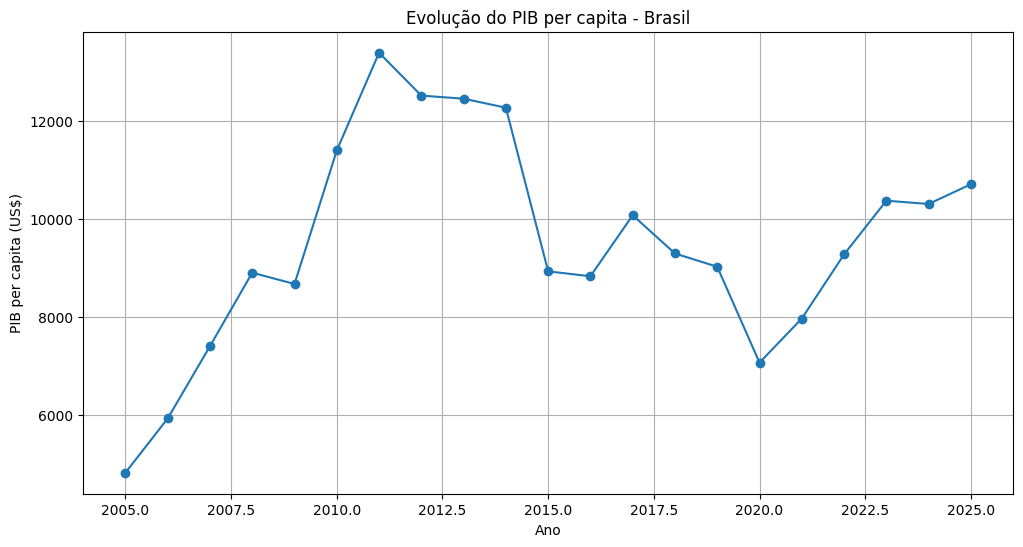

In [10]:
# 9. EVOLUÇÃO DO PIB PER CAPITA

brasil = df[df["Codigo"] == "BRA"]

plt.figure(figsize=(12, 6))

plt.plot(
    brasil["Ano"],
    brasil["PIB_per_capita"],
    marker="o"
)

plt.title("Evolução do PIB per capita - Brasil")
plt.xlabel("Ano")
plt.ylabel("PIB per capita (US$)")
plt.grid(True)

plt.show()


In [11]:
# 10. VARIÁVEIS DO MODELO

features = [
    "Populacao",
    "Crescimento_PIB",
    "Inflacao",
    "Desemprego",
    "Urbanizacao",
    "Acesso_Internet"
]

target = "PIB_per_capita"

X = df[features]

y = df[target]

print("Variáveis independentes:")
print(features)

print("\nVariável dependente:")
print(target)


Variáveis independentes:
['Populacao', 'Crescimento_PIB', 'Inflacao', 'Desemprego', 'Urbanizacao', 'Acesso_Internet']

Variável dependente:
PIB_per_capita


In [12]:
# 11. REMOVER LINHAS SEM TARGET

dados_modelo = df.dropna(
    subset=[target]
).copy()

X = dados_modelo[features]

y = dados_modelo[target]

print("Registros utilizados:", len(dados_modelo))


Registros utilizados: 629


In [13]:
# 12. TREINO E TESTE POR PERÍODO
#2005–2020 =treinamento
#2021–2024 =teste

treino = dados_modelo[
    dados_modelo["Ano"] <= 2020
].copy()

teste = dados_modelo[
    dados_modelo["Ano"] > 2020
].copy()

X_train = treino[features]
y_train = treino[target]

X_test = teste[features]
y_test = teste[target]

print("Treinamento:", len(treino))
print("Teste:", len(teste))


Treinamento: 480
Teste: 149


Fitting 3 folds for each of 20 candidates, totalling 60 fits
\nMelhores parâmetros — RandomizedSearchCV:
{'modelo__n_estimators': 100, 'modelo__min_samples_split': 2, 'modelo__min_samples_leaf': 2, 'modelo__max_features': 1.0, 'modelo__max_depth': 15}
Geração 1/5 — melhor MAE de validação: US$ 7,006.98
Geração 2/5 — melhor MAE de validação: US$ 6,939.59
Geração 3/5 — melhor MAE de validação: US$ 6,939.59
Geração 4/5 — melhor MAE de validação: US$ 6,869.64
Geração 5/5 — melhor MAE de validação: US$ 6,869.64
\nMelhores parâmetros — Algoritmo Genético:
{'n_estimators': 400, 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'max_features': 1.0}
\nComparação das métricas no conjunto de teste:
            Método           MAE          RMSE     R²
Random Forest base US$ 19,267.90 US$ 24,256.34 0.3241
RandomizedSearchCV US$ 19,826.81 US$ 24,725.84 0.2977
Algoritmo Genético US$ 19,402.61 US$ 24,406.53 0.3157


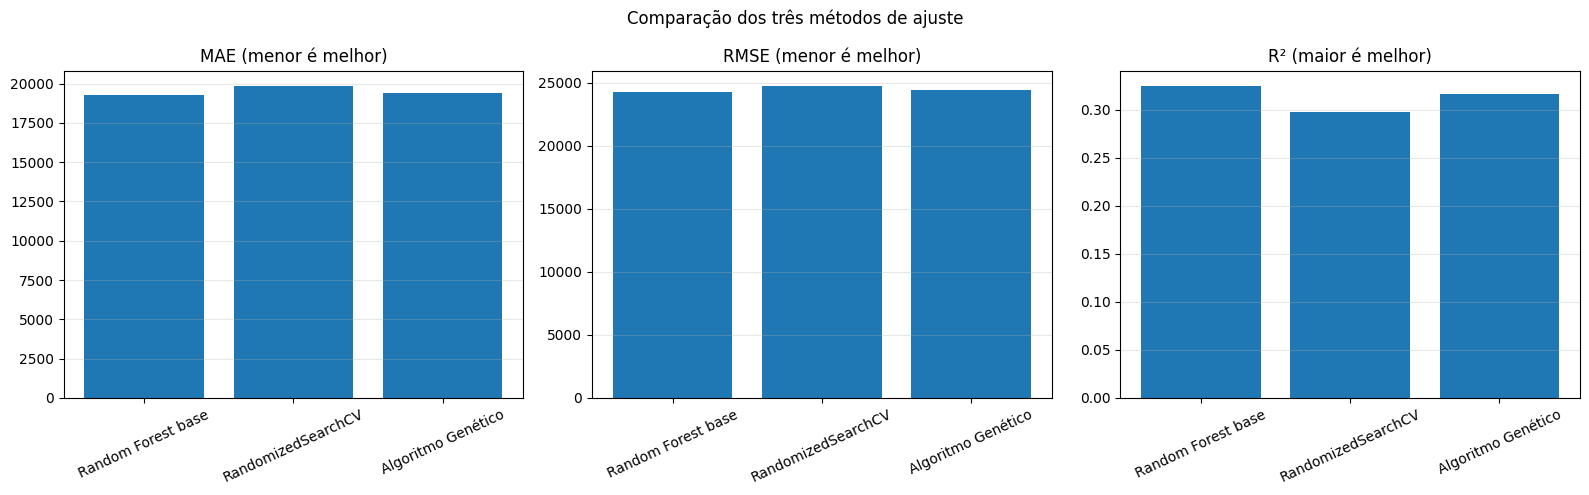

\nINTERPRETAÇÃO DAS MÉTRICAS
- Menor MAE: Random Forest base (erro absoluto médio de US$ 19,267.90).
- Menor RMSE: Random Forest base (penaliza mais os erros grandes; valor US$ 24,256.34).
- Maior R²: Random Forest base (R² = 0.3241).
MAE e RMSE devem ser menores; R² deve ser maior. R² próximo de 1 indica melhor ajuste,
próximo de 0 indica pouca explicação da variação e negativo indica desempenho pior que prever a média.
\nMétricas do modelo base:
MAE:  US$ 19,267.90
RMSE: US$ 24,256.34
R²:   0.3241


In [14]:
# 13. COMPARAÇÃO DE TRÊS MÉTODOS DE AJUSTE
# Método 1: Random Forest com hiperparâmetros definidos manualmente
# Método 2: RandomizedSearchCV
# Método 3: Algoritmo Genético (implementação simples)

from sklearn.model_selection import RandomizedSearchCV, KFold, cross_val_score
from sklearn.base import clone
import random

cv = KFold(n_splits=3, shuffle=True, random_state=42)

def criar_pipeline(parametros=None):
    """Cria pipeline com imputação, padronização e Random Forest."""
    parametros = parametros or {}
    rf_params = {
        "n_estimators": parametros.get("n_estimators", 300),
        "max_depth": parametros.get("max_depth", 10),
        "min_samples_leaf": parametros.get("min_samples_leaf", 2),
        "min_samples_split": parametros.get("min_samples_split", 2),
        "max_features": parametros.get("max_features", 1.0),
        "random_state": 42,
        "n_jobs": -1
    }
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("modelo", RandomForestRegressor(**rf_params))
    ])

def avaliar_modelo(nome, estimador):
    pred = estimador.predict(X_test)
    return {
        "Método": nome,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
        "Previsões": pred
    }

# Método 1 — modelo base
modelo_base = criar_pipeline({
    "n_estimators": 300,
    "max_depth": 10,
    "min_samples_leaf": 2
})
modelo_base.fit(X_train, y_train)

# Método 2 — busca aleatória de hiperparâmetros
espaco_parametros = {
    "modelo__n_estimators": [100, 200, 300, 400, 500],
    "modelo__max_depth": [None, 5, 8, 10, 15, 20],
    "modelo__min_samples_leaf": [1, 2, 3, 4, 5],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__max_features": [1.0, "sqrt", 0.8]
}
busca_aleatoria = RandomizedSearchCV(
    estimator=criar_pipeline(),
    param_distributions=espaco_parametros,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
busca_aleatoria.fit(X_train, y_train)
modelo_random = busca_aleatoria.best_estimator_
print("\\nMelhores parâmetros — RandomizedSearchCV:")
print(busca_aleatoria.best_params_)

# Método 3 — algoritmo genético simples
# Cada indivíduo representa uma combinação de hiperparâmetros.
espaco_genetico = {
    "n_estimators": [100, 200, 300, 400, 500],
    "max_depth": [None, 5, 8, 10, 15, 20],
    "min_samples_leaf": [1, 2, 3, 4, 5],
    "min_samples_split": [2, 5, 10],
    "max_features": [1.0, "sqrt", 0.8]
}
random.seed(42)
np.random.seed(42)

def individuo_aleatorio():
    return {k: random.choice(v) for k, v in espaco_genetico.items()}

def aptidao(individuo):
    estimador = criar_pipeline(individuo)
    scores = cross_val_score(
        estimador, X_train, y_train,
        scoring="neg_mean_absolute_error",
        cv=cv, n_jobs=1
    )
    return -scores.mean()  # menor MAE é melhor

def cruzamento(pai1, pai2):
    return {k: random.choice([pai1[k], pai2[k]]) for k in espaco_genetico}

def mutacao(individuo, taxa=0.2):
    novo = individuo.copy()
    for chave, opcoes in espaco_genetico.items():
        if random.random() < taxa:
            novo[chave] = random.choice(opcoes)
    return novo

tamanho_populacao = 8
geracoes = 5
populacao = [individuo_aleatorio() for _ in range(tamanho_populacao)]

for geracao in range(geracoes):
    pontuados = sorted([(aptidao(ind), ind) for ind in populacao], key=lambda x: x[0])
    melhor_mae, melhor_individuo = pontuados[0]
    print(f"Geração {geracao + 1}/{geracoes} — melhor MAE de validação: US$ {melhor_mae:,.2f}")
    elite = [ind for _, ind in pontuados[:2]]
    nova_populacao = elite.copy()
    while len(nova_populacao) < tamanho_populacao:
        torneio = random.sample(pontuados[:max(2, tamanho_populacao // 2)], 2)
        pai1, pai2 = torneio[0][1], torneio[1][1]
        nova_populacao.append(mutacao(cruzamento(pai1, pai2)))
    populacao = nova_populacao

pontuados = sorted([(aptidao(ind), ind) for ind in populacao], key=lambda x: x[0])
melhores_parametros_genetico = pontuados[0][1]
modelo_genetico = criar_pipeline(melhores_parametros_genetico)
modelo_genetico.fit(X_train, y_train)
print("\\nMelhores parâmetros — Algoritmo Genético:")
print(melhores_parametros_genetico)

# Avaliação dos três métodos no mesmo conjunto de teste
modelos = [
    ("Random Forest base", modelo_base),
    ("RandomizedSearchCV", modelo_random),
    ("Algoritmo Genético", modelo_genetico)
]
avaliacoes = []
for nome, estimador in modelos:
    avaliacoes.append(avaliar_modelo(nome, estimador))

metricas = pd.DataFrame([
    {k: v for k, v in item.items() if k != "Previsões"}
    for item in avaliacoes
])
print("\\nComparação das métricas no conjunto de teste:")
print(metricas.to_string(index=False, formatters={
    "MAE": lambda x: f"US$ {x:,.2f}",
    "RMSE": lambda x: f"US$ {x:,.2f}",
    "R²": lambda x: f"{x:.4f}"
}))

# Gráfico comparativo das métricas
fig, eixos = plt.subplots(1, 3, figsize=(16, 5))
for eixo, metrica, titulo in zip(
    eixos,
    ["MAE", "RMSE", "R²"],
    ["MAE (menor é melhor)", "RMSE (menor é melhor)", "R² (maior é melhor)"]
):
    eixo.bar(metricas["Método"], metricas[metrica])
    eixo.set_title(titulo)
    eixo.tick_params(axis="x", rotation=25)
    eixo.grid(axis="y", alpha=0.3)
plt.suptitle("Comparação dos três métodos de ajuste")
plt.tight_layout()
plt.savefig("comparacao_tres_metodos.png", dpi=150, bbox_inches="tight")
plt.show()

# Explicação automática com base nos valores obtidos
melhor_mae_linha = metricas.loc[metricas["MAE"].idxmin()]
melhor_rmse_linha = metricas.loc[metricas["RMSE"].idxmin()]
melhor_r2_linha = metricas.loc[metricas["R²"].idxmax()]
print("\\nINTERPRETAÇÃO DAS MÉTRICAS")
print(f"- Menor MAE: {melhor_mae_linha['Método']} (erro absoluto médio de US$ {melhor_mae_linha['MAE']:,.2f}).")
print(f"- Menor RMSE: {melhor_rmse_linha['Método']} (penaliza mais os erros grandes; valor US$ {melhor_rmse_linha['RMSE']:,.2f}).")
print(f"- Maior R²: {melhor_r2_linha['Método']} (R² = {melhor_r2_linha['R²']:.4f}).")
print("MAE e RMSE devem ser menores; R² deve ser maior. R² próximo de 1 indica melhor ajuste,")
print("próximo de 0 indica pouca explicação da variação e negativo indica desempenho pior que prever a média.")

# Mantém o modelo base como referência para as análises seguintes do script
modelo = modelo_base
y_pred = modelo.predict(X_test)

resultado = teste[["Pais", "Codigo", "Ano", "PIB_per_capita"]].copy()
resultado["PIB_Previsto"] = y_pred
resultado["Erro"] = resultado["PIB_per_capita"] - resultado["PIB_Previsto"]

# Métricas do modelo base, para manter a seção de avaliação individual
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("\\nMétricas do modelo base:")
print(f"MAE:  US$ {mae:,.2f}")
print(f"RMSE: US$ {rmse:,.2f}")
print(f"R²:   {r2:.4f}")


In [15]:
# 17. REAL X PREVISTO

comparacao = resultado[
    [
        "Pais",
        "Ano",
        "PIB_per_capita",
        "PIB_Previsto"
    ]
].copy()

comparacao["Erro_%"] = (
    abs(
        comparacao["PIB_per_capita"]
        - comparacao["PIB_Previsto"]
    )
    / comparacao["PIB_per_capita"]
) * 100

comparacao = comparacao.sort_values(
    ["Pais", "Ano"]
)

comparacao.head(30)


,Pais,Ano,PIB_per_capita,PIB_Previsto,Erro_%
61,Alemanha,2021,52349.245999,41230.136849,21.240247
62,Alemanha,2022,50506.517964,40399.014525,20.012275
63,Alemanha,2023,54776.766824,40707.288025,25.685121
64,Alemanha,2024,56103.732318,44146.932595,21.311951
65,Alemanha,2025,60496.435082,31608.929897,47.750756
127,Argentina,2021,10738.017922,37005.707800,244.623264
128,Argentina,2022,13962.189409,39495.670927,182.875914
129,Argentina,2023,14261.846567,38093.321510,167.099504
130,Argentina,2024,13969.783660,39823.205044,185.066727
131,Argentina,2025,14898.088594,19134.860778,28.438361


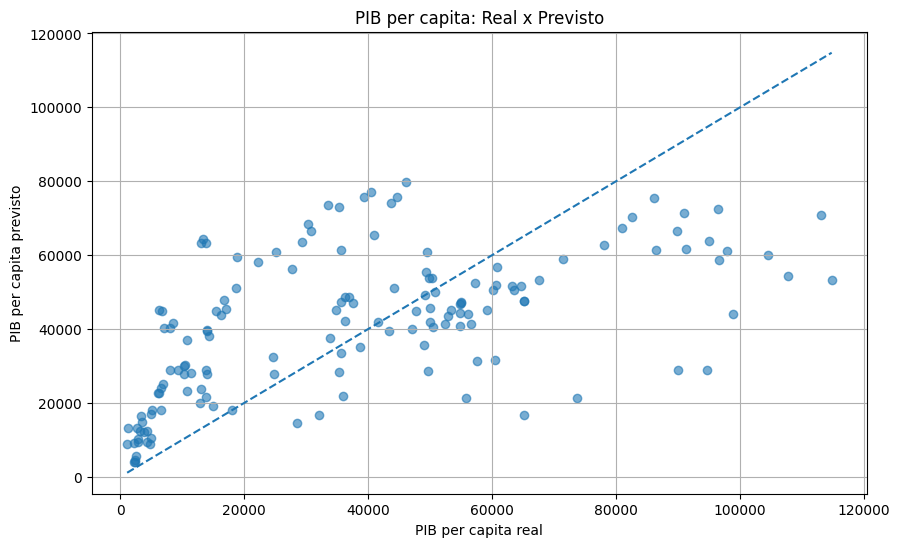

In [16]:
# 18. GRÁFICO REAL X PREVISTO

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

# Linha ideal
limite_min = min(
    y_test.min(),
    y_pred.min()
)

limite_max = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("PIB per capita real")
plt.ylabel("PIB per capita previsto")

plt.title(
    "PIB per capita: Real x Previsto"
)

plt.grid(True)

plt.show()


   Indicador  Importancia
4  Feature_4     0.651297
3  Feature_3     0.178857
0  Feature_0     0.082911
2  Feature_2     0.051166
1  Feature_1     0.035769


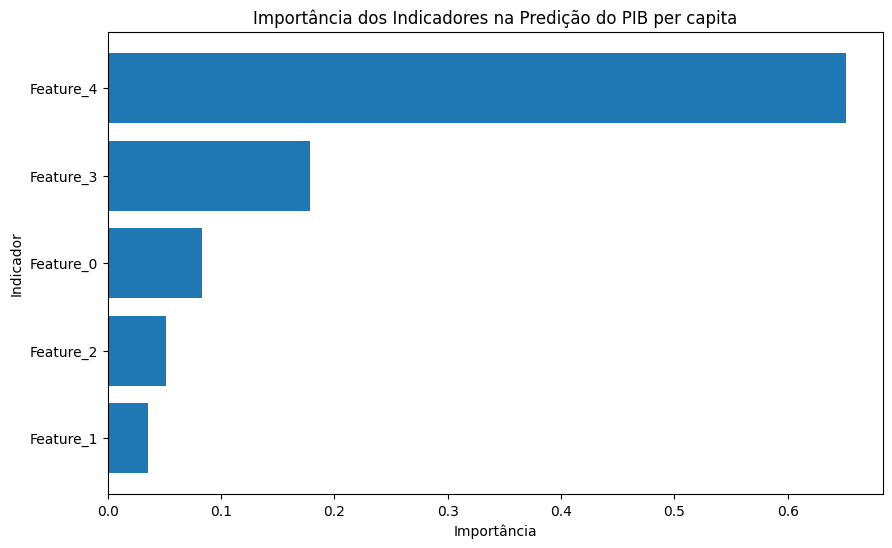

In [17]:
# 19. IMPORTÂNCIA DAS VARIÁVEIS

rf = modelo.named_steps["modelo"]
importancias_valores = rf.feature_importances_

# Garante o mapeamento das colunas associando com as colunas de treino disponíveis
colunas_treino = list(X_train.columns)

# Caso o número de importâncias seja diferente (por exemplo, se colunas foram alteradas no pré-processamento)
if len(importancias_valores) == len(colunas_treino):
    nomes_features = colunas_treino
else:
    nomes_features = [f"Feature_{i}" for i in range(len(importancias_valores))]

importancias = pd.DataFrame({
    "Indicador": nomes_features,
    "Importancia": importancias_valores
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias)

plt.figure(figsize=(10, 6))

plt.barh(
    importancias["Indicador"],
    importancias["Importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Indicador")

plt.title(
    "Importância dos Indicadores na Predição do PIB per capita"
)

plt.gca().invert_yaxis()

plt.show()


In [18]:
# 20. PREVISÃO PARA O BRASIL

brasil = dados_modelo[
    dados_modelo["Codigo"] == "BRA"
].copy()

ultimo_brasil = brasil.sort_values(
    "Ano"
).tail(1)

X_brasil = ultimo_brasil[features]

previsao_brasil = modelo.predict(
    X_brasil
)[0]

print("PREVISÃO - BRASIL")

print(
    "Ano dos indicadores:",
    int(ultimo_brasil["Ano"].iloc[0])
)

print(
    "PIB per capita real:",
    f"US$ {ultimo_brasil['PIB_per_capita'].iloc[0]:,.2f}"
)

print(
    "PIB per capita previsto:",
    f"US$ {previsao_brasil:,.2f}"
)


PREVISÃO - BRASIL
Ano dos indicadores: 2025
PIB per capita real: US$ 10,713.29
PIB per capita previsto: US$ 23,273.92


In [19]:
# 21. SALVAR DATASET

df.to_csv(
    "dados_pib_mundo_banco_mundial.csv",
    index=False,
    encoding="utf-8-sig"
)

resultado.to_csv(
    "previsoes_pib_per_capita.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos CSV salvos com sucesso!")

#https://data.worldbank.org/indicator/NY.GDP.PCAP.CD

#https://datahelpdesk.worldbank.org/knowledgebase/articles/898581-api-basic-call-structures


Arquivos CSV salvos com sucesso!


In [20]:
pip install joblib

In [22]:
import joblib
from pathlib import Path

# Criar a pasta para o modelo se não existir
Path("modelo").mkdir(exist_ok=True)

# Salvar o modelo treinado (usando a variável 'modelo' que está definida no seu ambiente)
joblib.dump(modelo, "modelo/modelo_pib_per_capita.joblib", compress=3)


['modelo/modelo_pib_per_capita.joblib']

In [23]:
joblib.dump({"modelo": modelo_genetico, "features": features}, "modelo/modelo.joblib")


['modelo/modelo.joblib']

In [27]:
import joblib
import pandas as pd
import numpy as np

pacote = joblib.load("modelo/modelo_pib_per_capita.joblib")
modelo = pacote

# Criando o DataFrame com as 6 features exigidas no treinamento original
entrada = pd.DataFrame([{
    "Populacao": 215_000_000,
    "Crescimento_PIB": 2.9,
    "Inflacao": 4.6,
    "Desemprego": 8.0,
    "Urbanizacao": 87.0,
    "Acesso_Internet": np.nan  # O SimpleImputer do pipeline preencherá automaticamente
}])

print("PIB per capita previsto:", modelo.predict(entrada)[0])

PIB per capita previsto: 25008.918025588595


In [29]:
!pip install streamlit
!streamlit run app.py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 38.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 49.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]
Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: app.py


In [31]:
import streamlit as st
import joblib

@st.cache_resource
def carregar_modelo():
    return joblib.load("modelo/modelo_pib_per_capita.joblib")

In [33]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib

st.set_page_config(page_title="Previsão do PIB per Capita", layout="centered")

st.title("🔮 Predição do PIB per Capita")
st.write("Insira os indicadores econômicos abaixo para estimar o PIB per capita correspondente.")

@st.cache_resource
def carregar_modelo():
    return joblib.load("modelo/modelo_pib_per_capita.joblib")

modelo = carregar_modelo()

# Criando formulário de entrada para o usuário
with st.form("formulario_predicao"):
    col1, col2 = st.columns(2)

    with col1:
        populacao = st.number_input("População Total", min_value=1000, value=215000000, step=1000000, format="%d")
        crescimento_pib = st.number_input("Crescimento anual do PIB (%)", value=2.9, step=0.1)
        inflacao = st.number_input("Inflação (%) ", value=4.6, step=0.1)

    with col2:
        desemprego = st.number_input("Taxa de Desemprego (%)", value=8.0, step=0.1)
        urbanizacao = st.number_input("Taxa de Urbanização (%)", min_value=0.0, max_value=100.0, value=87.0, step=0.5)
        acesso_internet = st.number_input("Acesso à Internet (%)", min_value=0.0, max_value=100.0, value=81.0, step=0.5)

    botao_enviar = st.form_submit_button("Realizar Previsão")

if botao_enviar:
    # Criando o DataFrame no formato esperado pelo pipeline (com as 6 features)
    entrada = pd.DataFrame([{
        "Populacao": populacao,
        "Crescimento_PIB": crescimento_pib,
        "Inflacao": inflacao,
        "Desemprego": desemprego,
        "Urbanizacao": urbanizacao,
        "Acesso_Internet": acesso_internet
    }])

    # Realizar a predição
    previsao = modelo.predict(entrada)[0]

    st.success(f"### 💰 PIB per capita previsto: US$ {previsao:,.2f}")

Writing app.py


In [34]:
import pandas as pd
import numpy as np
import joblib

# Carrega o modelo de forma segura no notebook
modelo = joblib.load("modelo/modelo_pib_per_capita.joblib")

# Criamos um dicionário local com valores padrões simulando as entradas
valores_entrada = {
    "Populacao": 215_000_000,
    "Crescimento_PIB": 2.9,
    "Inflacao": 4.6,
    "Desemprego": 8.0,
    "Urbanizacao": 87.0,
    "Acesso_Internet": np.nan
}

# Criando o DataFrame no formato que o modelo espera
entrada = pd.DataFrame([valores_entrada])
previsto = float(modelo.predict(entrada)[0])

print(f"PIB per capita previsto no Notebook: US$ {previsto:,.2f}")

PIB per capita previsto no Notebook: US$ 25,008.92


In [35]:
import joblib
import pandas as pd
import streamlit as st

st.title("Previsão do PIB per capita")
modelo = joblib.load("modelo/modelo_pib_per_capita.joblib")["modelo"]

pop = st.number_input("População", value=200_000_000.0, step=1_000_000.0)
cresc = st.number_input("Crescimento do PIB (%)", value=2.0)
infl = st.number_input("Inflação (%)", value=5.0)
desemp = st.number_input("Desemprego (%)", value=8.0)
urb = st.slider("Urbanização (%)", 0.0, 100.0, 80.0)
net = st.slider("Acesso à internet (%)", 0.0, 100.0, 75.0)

if st.button("Prever"):
    entrada = pd.DataFrame([{
        "Populacao": pop, "Crescimento_PIB": cresc, "Inflacao": infl,
        "Desemprego": desemp, "Urbanizacao": urb, "Acesso_Internet": net,
    }])
    st.success(f"PIB per capita previsto: US$ {modelo.predict(entrada)[0]:,.0f}")

2026-11-12 22:12:32.578 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 22:12:32.789 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-12 22:12:32.791 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 22:12:32.794 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 22:12:32.901 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 22:12:32.902 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 22:12:32.904 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-12 22:12:32.907 Thread 'MainThread': mi

In [38]:
from pathlib import Path
import joblib
import streamlit as st

ARQUIVO_MODELO = Path("modelo/modelo.joblib")

# Limpa o cache para garantir que não use lixo de execuções anteriores
st.cache_resource.clear()

@st.cache_resource
def carregar_modelo():
    return joblib.load(ARQUIVO_MODELO)

if not ARQUIVO_MODELO.exists():
    st.error("Modelo não encontrado. Certifique-se de que o arquivo 'modelo/modelo.joblib' existe.")
    st.stop()

pacote = carregar_modelo()

if isinstance(pacote, dict) and "modelo" in pacote:
    modelo = pacote["modelo"]        # pipeline: imputação + padronização + Random Forest
    features = pacote["features"]    # ordem e nomes das colunas usadas no treino
    print("Sucesso! Modelo e features carregados com sucesso.")
    print("Features detectadas:", features)
else:
    st.error("O arquivo carregado não contém a estrutura de chaves esperada.")

2026-11-12 22:16:10.318 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Sucesso! Modelo e features carregados com sucesso.
Features detectadas: ['Populacao', 'Crescimento_PIB', 'Inflacao', 'Desemprego', 'Urbanizacao', 'Acesso_Internet']


In [39]:
previsto = modelo.predict(entrada)[0]

In [40]:
### Estrutura do Projeto

```text
projeto-pib-per-capita/
├── app.py
└── modelo/
    └── modelo_pib_per_capita.joblib
```

SyntaxError: invalid character '├' (U+251C) (3499996646.py, line 2)

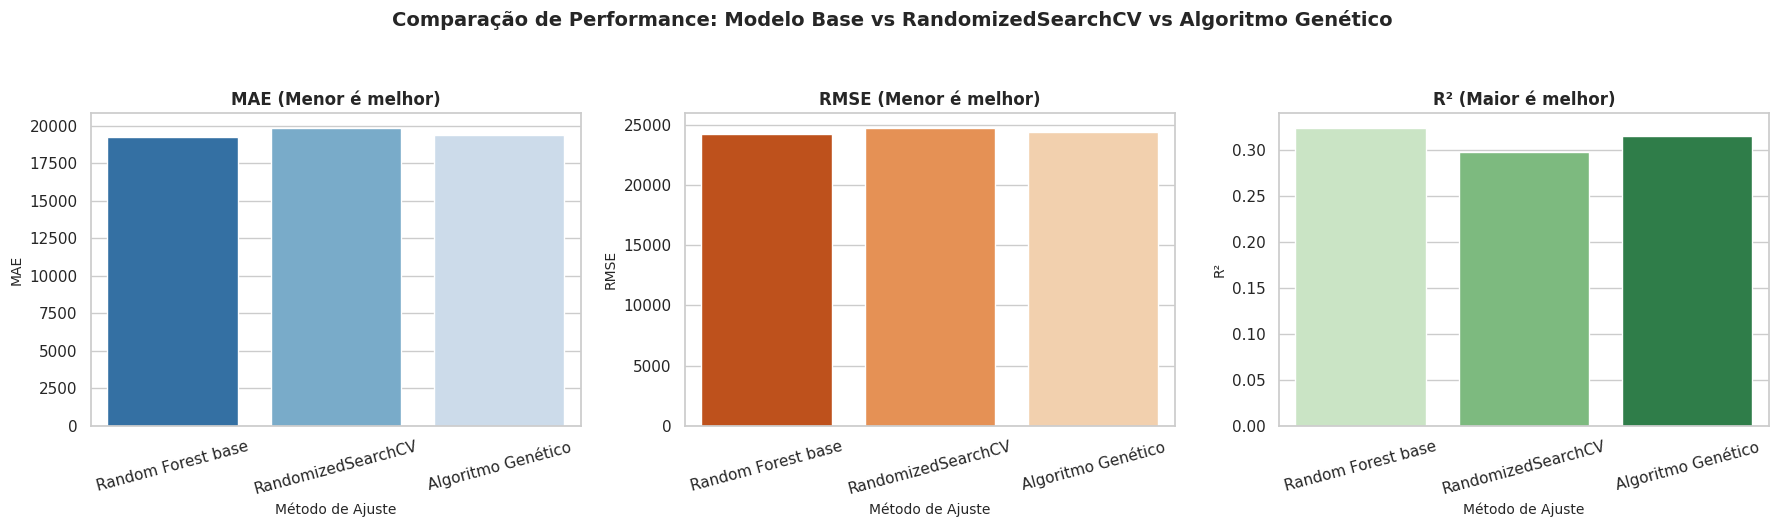

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definindo o estilo visual do gráfico
sns.set_theme(style="whitegrid")

# Criando a estrutura de subplots (1 linha, 3 colunas) para comparar as 3 métricas principais
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Lista de métricas e suas respectivas configurações de visualização
configs = [
    ("MAE", "MAE (Menor é melhor)", "Blues_r"),
    ("RMSE", "RMSE (Menor é melhor)", "Oranges_r"),
    ("R²", "R² (Maior é melhor)", "Greens")
]

for ax, (coluna, titulo, paleta) in zip(axes, configs):
    # Criando o gráfico de barras para cada métrica
    sns.barplot(
        x="Método",
        y=coluna,
        data=metricas,
        ax=ax,
        palette=paleta,
        hue="Método",
        legend=False
    )
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel("Método de Ajuste", fontsize=10)
    ax.set_ylabel(coluna, fontsize=10)
    ax.tick_params(axis='x', rotation=15)

plt.suptitle("Comparação de Performance: Modelo Base vs RandomizedSearchCV vs Algoritmo Genético", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()